In [3]:
# for auto reloading  
%load_ext autoreload
%autoreload 2

# for importing from parent folder 
import sys
sys.path.append('..')

# import necessary packages 
import numpy as np
import matplotlib.pyplot as plt 
# import scipy.stats as st

# my packages
import stoch_models
import numerical_schemes
# import path_simulation
import option_contracts
# import estimators
import pricing_engine
import analytical_results


import randomness
import importance_sampling


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:

# Model
model = stoch_models.GBM(r=0.05, sigma=0.2)

S_0 = 100
N = 100_000
M = 1
T = 1.0

# OTM option
option = option_contracts.EuropeanCall(
    strike=150,
    maturity=T,
)

times = np.linspace(0, T, M + 1)

rng = np.random.default_rng(100)
# rng = np.random
Z = rng.standard_normal(size=(N, M))

# Determine the shift
theta = importance_sampling.gbm_strike_shift(
    model=model,
    product=option,
    S_0=S_0,
)

# Generate shifted draws and weights
sampling = randomness.constant_drift_shift(
    normal_draws=Z,
    times=times,
    theta=theta,
)

# Importance sampling price
result_is = pricing_engine.price_option(
    model=model,
    product=option,
    scheme=numerical_schemes.exact_step,
    S_0=S_0,
    N=N,
    times=times,
    normal_draws=sampling.normal_draws,
    weights=sampling.weights,
)

print(f"Shift:          {theta:.6f}")
print(f"Price:          {result_is.price:.6f}")
print(f"Standard error: {result_is.standard_error:.6f}")
print(f"95% CI:         {result_is.confidence_interval}")


Shift:          1.877326
Price:          0.359002
Standard error: 0.001289
95% CI:         (np.float64(0.35647479010260763), np.float64(0.36152925250263346))


In [5]:
result_mc = pricing_engine.price_option(
    model=model,
    product=option,
    scheme=numerical_schemes.exact_step,
    S_0=S_0,
    N=N,
    times=times,
    normal_draws=Z,
)


# Analytical benchmark
bs_price = analytical_results.black_scholes_price(
    model=model,
    product=option,
    S_0=S_0,
)

print(f"Price:          {result_mc.price:.6f}")
print(f"Standard error: {result_mc.standard_error:.6f}")
# print(f"95% CI:         {result_mc.confidence_interval}")

variance_reduction = (
    result_mc.sample_variance
    / result_is.sample_variance
)

print(f"Variance reduction factor: {variance_reduction:.2f}")

z_mc = (result_mc.price - bs_price) / result_mc.standard_error
z_is = (result_is.price - bs_price) / result_is.standard_error

print(f"MC standardized error: {z_mc:.4f}")
print(f"IS standardized error: {z_is:.4f}")


Price:          0.353160
Standard error: 0.008853
Variance reduction factor: 47.14
MC standardized error: -0.7308
IS standardized error: -0.4869


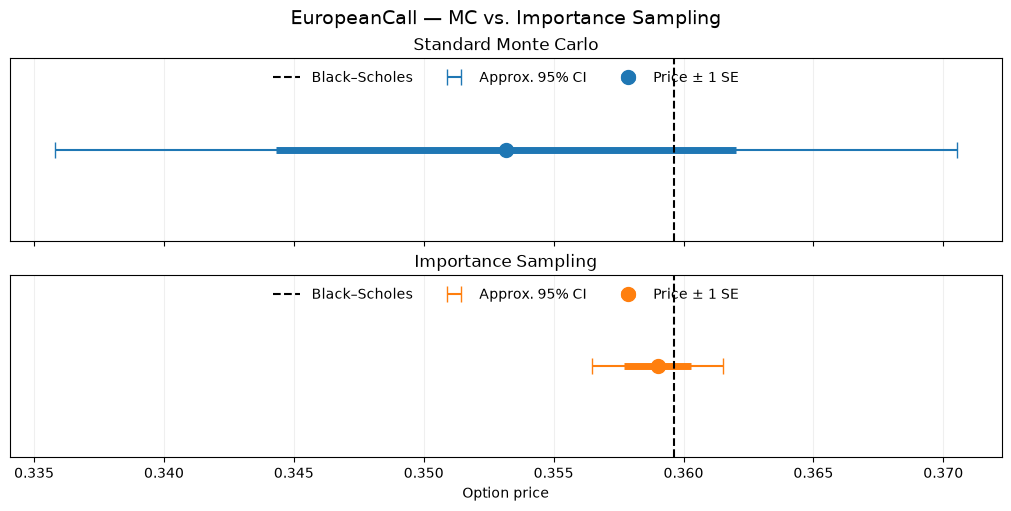

In [6]:

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 5),
    sharex=True,
    constrained_layout=True,
)

results = [
    (result_mc, "Standard Monte Carlo", "tab:blue"),
    (result_is, "Importance Sampling", "tab:orange"),
]

for ax, (result, title, color) in zip(axes, results):

    price = result.price
    se = result.standard_error

    # Approximate 95% confidence interval
    ax.errorbar(
        price, 0,
        xerr=[
            [price - result.ci_lower],
            [result.ci_upper - price],
        ],
        fmt="none",
        ecolor=color,
        capsize=6,
        label="Approx. 95% CI",
    )

    # Estimated price ± 1 standard error
    ax.errorbar(
        price, 0,
        xerr=se,
        fmt="o",
        markersize=10,
        color=color,
        elinewidth=5,
        label="Price ± 1 SE",
    )

    # Analytical benchmark
    ax.axvline(
        bs_price,
        color="black",
        linestyle="--",
        label="Black–Scholes",
    )

    ax.set(
        title=title,
        ylim=(-1, 1),
    )

    ax.set_yticks([])
    ax.legend(loc="upper center", ncol=3, frameon=False)
    ax.grid(axis="x", alpha=0.2)

axes[-1].set_xlabel("Option price")

fig.suptitle(
    f"{type(option).__name__} — MC vs. Importance Sampling",
    fontsize=14,
)

plt.show()
